---

## Track K — E-commerce Return Rate Forecasting

### The Story

**RetailLoop** is an e-commerce platform that manages product campaigns for
thousands of sellers.  Every campaign involves a significant upfront investment:
creating product listings, sourcing inventory, and running marketing spend.
Return rates — the percentage of delivered items that are sent back — are one
of the biggest drags on campaign profitability, and they vary enormously across
product types, price points, and presentation quality.

The merchandising team wants to be able to forecast a campaign's return rate
before it launches, using information that is already available at campaign
creation time: product characteristics, listing quality, fulfillment estimates,
and past sales context.  A model that can flag high-risk campaigns early gives
the team time to improve the listing, adjust the price, or warn the seller
before inventory is committed.

For RetailLoop, the value of return rate forecasting is upstream: it shapes
decisions that are made before a campaign goes live and before inventory is
committed.  A model that can reliably flag high-risk campaigns gives the
merchandising team time to intervene — improving a listing, adjusting a
price, or simply managing expectations with the seller.  Your task is to
build a model that is useful at that decision point, and to identify which
campaign characteristics most strongly drive return risk.

### Dataset Files

| File | Rows | Columns | Target |
|---|---|---|---|
| `track_k_ecommerce_returns_train.csv` | 1300 | 13 | `return_rate_pct` |
| `track_k_ecommerce_returns_test.csv` | 350 | 13 | `return_rate_pct` |

### Feature Reference

| Feature | Type | Range | Description |
|---|---|---|---|
| `price_eur` | float | 8–280 | Selling price in EUR. |
| `discount_pct` | float | 0–60 | Discount percentage. |
| `size_variants_count` | int | 1–12 | Number of available size variants. |
| `shipping_days` | float | 1–10 | Average shipping lead time. |
| `product_rating` | float | 2.2–5.0 | Product rating score. |
| `review_volume` | int | 5–600 | Number of reviews. |
| `image_quality_score` | float | 0–10 | Image quality score. |
| `description_quality_score` | float | 0–10 | Description quality score. |
| `size_mismatch_reports` | int | 0–35 | Historical mismatch report count. |
| `category_complexity_index` | float | 0–10 | Category complexity index. |
| `holiday_campaign_flag` | binary | 0/1 | Whether campaign runs in holiday period. |
| `packaging_color_code` | int | 1–6 | Packaging color category code. |
| **`return_rate_pct`** | float | 0–90 | **Target: expected return percentage.** |

---

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
np.random.RandomState(42)
df = pd.read_csv("data/track_k_ecommerce_returns_train.csv")

In [2]:
# df['holiday_campaign_flag'] = df['holiday_campaign_flag'].map(
# {1: True, 0: False}
# ).astype("category")


In [3]:
df.dtypes

price_eur                    float64
discount_pct                 float64
size_variants_count            int64
shipping_days                float64
product_rating               float64
review_volume                  int64
image_quality_score          float64
description_quality_score    float64
size_mismatch_reports          int64
category_complexity_index    float64
holiday_campaign_flag          int64
packaging_color_code           int64
return_rate_pct              float64
dtype: object

In [4]:
df.describe()

,price_eur,discount_pct,size_variants_count,shipping_days,product_rating,review_volume,image_quality_score,description_quality_score,size_mismatch_reports,category_complexity_index,holiday_campaign_flag,packaging_color_code,return_rate_pct
count,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000,1300.000000
mean,143.250631,29.976554,6.476154,5.319808,3.586992,140.546154,4.897954,5.977446,3.563077,4.964677,0.223077,3.468462,33.451762
std,78.916425,17.391667,3.400433,2.553168,0.800625,12.210378,2.845962,2.470796,1.854157,2.825049,0.416470,1.697189,23.006167
min,8.140000,0.030000,1.000000,1.010000,2.200000,102.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.200000
25%,73.622500,14.795000,4.000000,3.120000,2.900000,132.000000,2.370000,3.847500,2.000000,2.640000,0.000000,2.000000,13.590000
50%,141.545000,29.985000,6.500000,5.220000,3.600000,140.000000,4.890000,6.060000,3.000000,4.900000,0.000000,3.000000,25.195000
75%,213.002500,45.187500,9.000000,7.520000,4.252500,148.000000,7.260000,7.970000,5.000000,7.470000,0.000000,5.000000,57.625000
max,279.840000,59.990000,12.000000,10.000000,5.000000,184.000000,10.000000,10.000000,11.000000,9.990000,1.000000,6.000000,85.490000


<Axes: >

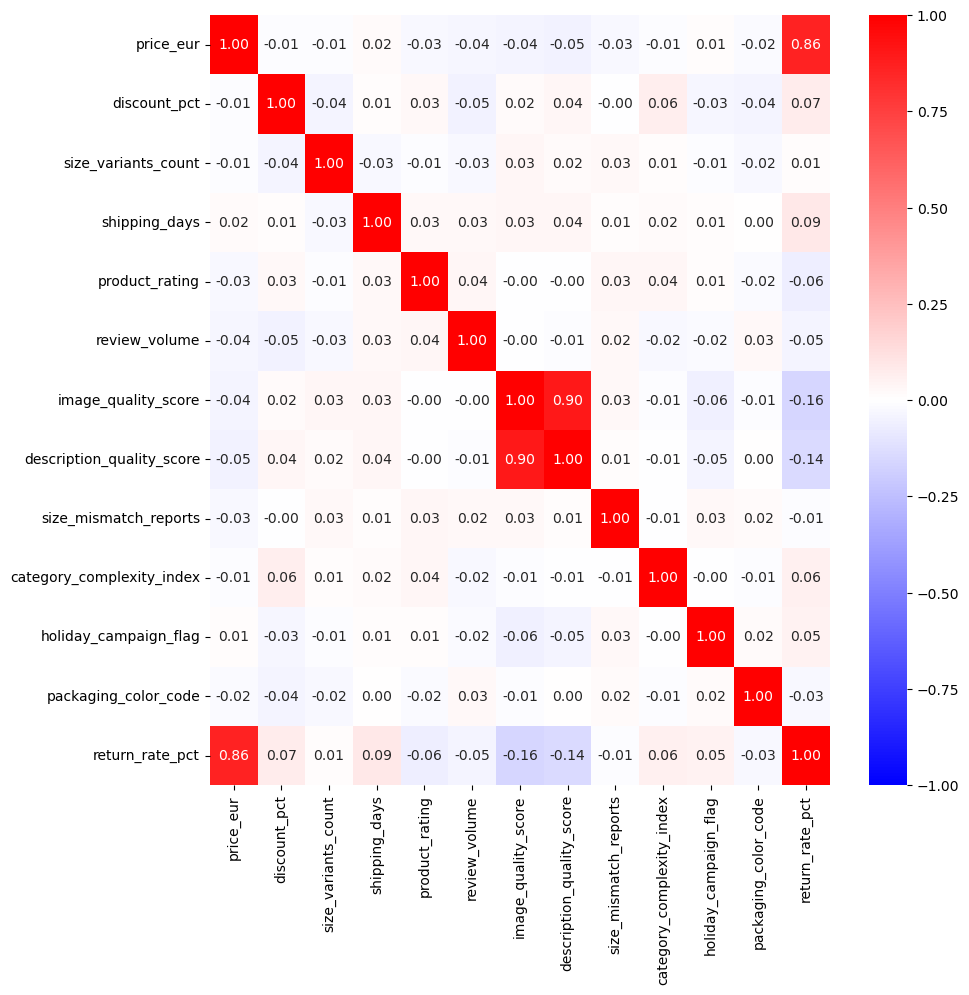

In [5]:
import seaborn as sns
fig = plt.figure(figsize=(10,10))
sns.heatmap(df.corr(), cmap="bwr", vmin ='-1', annot=True, fmt=".2f")

(array([ 10.,  31., 110., 239., 352., 321., 151.,  64.,  16.,   6.]),
 array([102. , 110.2, 118.4, 126.6, 134.8, 143. , 151.2, 159.4, 167.6,
        175.8, 184. ]),
 <BarContainer object of 10 artists>)

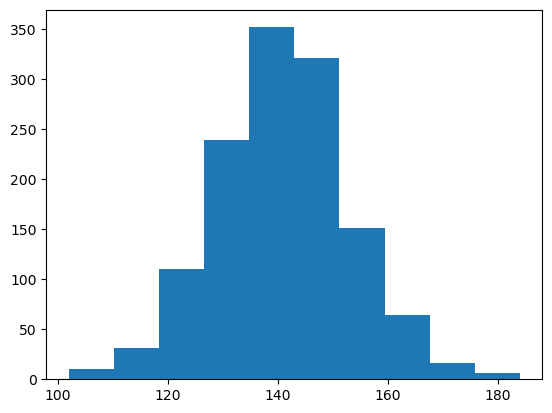

In [6]:
plt.hist(df['review_volume'])

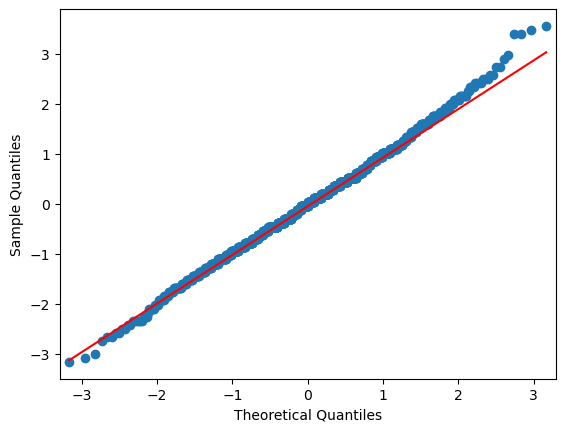

In [7]:
import statsmodels.api as sm
from scipy import stats
fig = sm.qqplot(df['review_volume'], stats.norm, fit=True, line='q')
plt.show()

<BarContainer object of 12 artists>

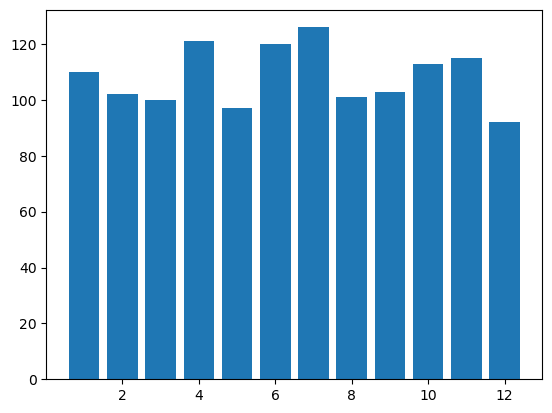

In [8]:
plt.bar(np.linspace(1, 12, 12), df['size_variants_count'].value_counts().sort_index())

((array([-3.27247685, -3.01288906, -2.86838246, ...,  2.86838246,
          3.01288906,  3.27247685], shape=(1300,)),
  array([ 1,  1,  1, ..., 12, 12, 12], shape=(1300,))),
 (np.float64(3.313126942099094),
  np.float64(6.4761538461538475),
  np.float64(0.9725489404447316)))

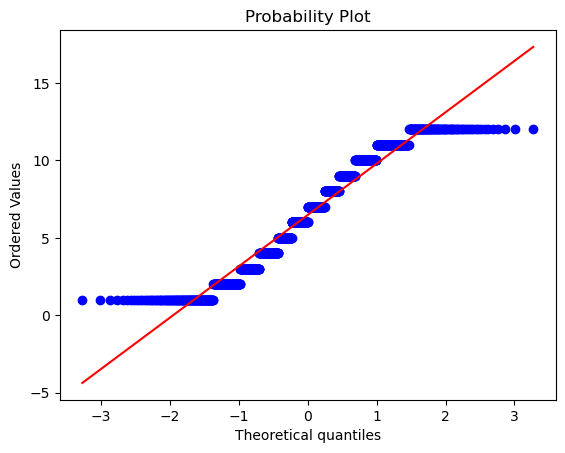

In [9]:
import statsmodels.api as sm
from scipy import stats

stats.probplot(df['size_variants_count'], dist='norm', plot=plt)

# fig = sm.qqplot(df['size_variants_count'], , fit=True, line='q')
# plt.show()

<BarContainer object of 12 artists>

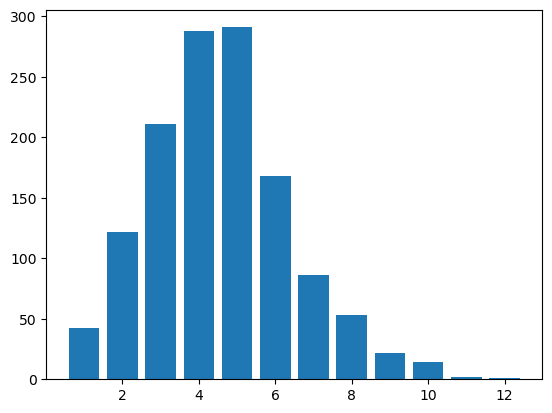

In [10]:
plt.bar(np.linspace(1, 12, 12), df['size_mismatch_reports'].value_counts().sort_index())

In [11]:
df['packaging_color_code'].value_counts().sort_index()

packaging_color_code
1    209
2    245
3    207
4    210
5    225
6    204
Name: count, dtype: int64

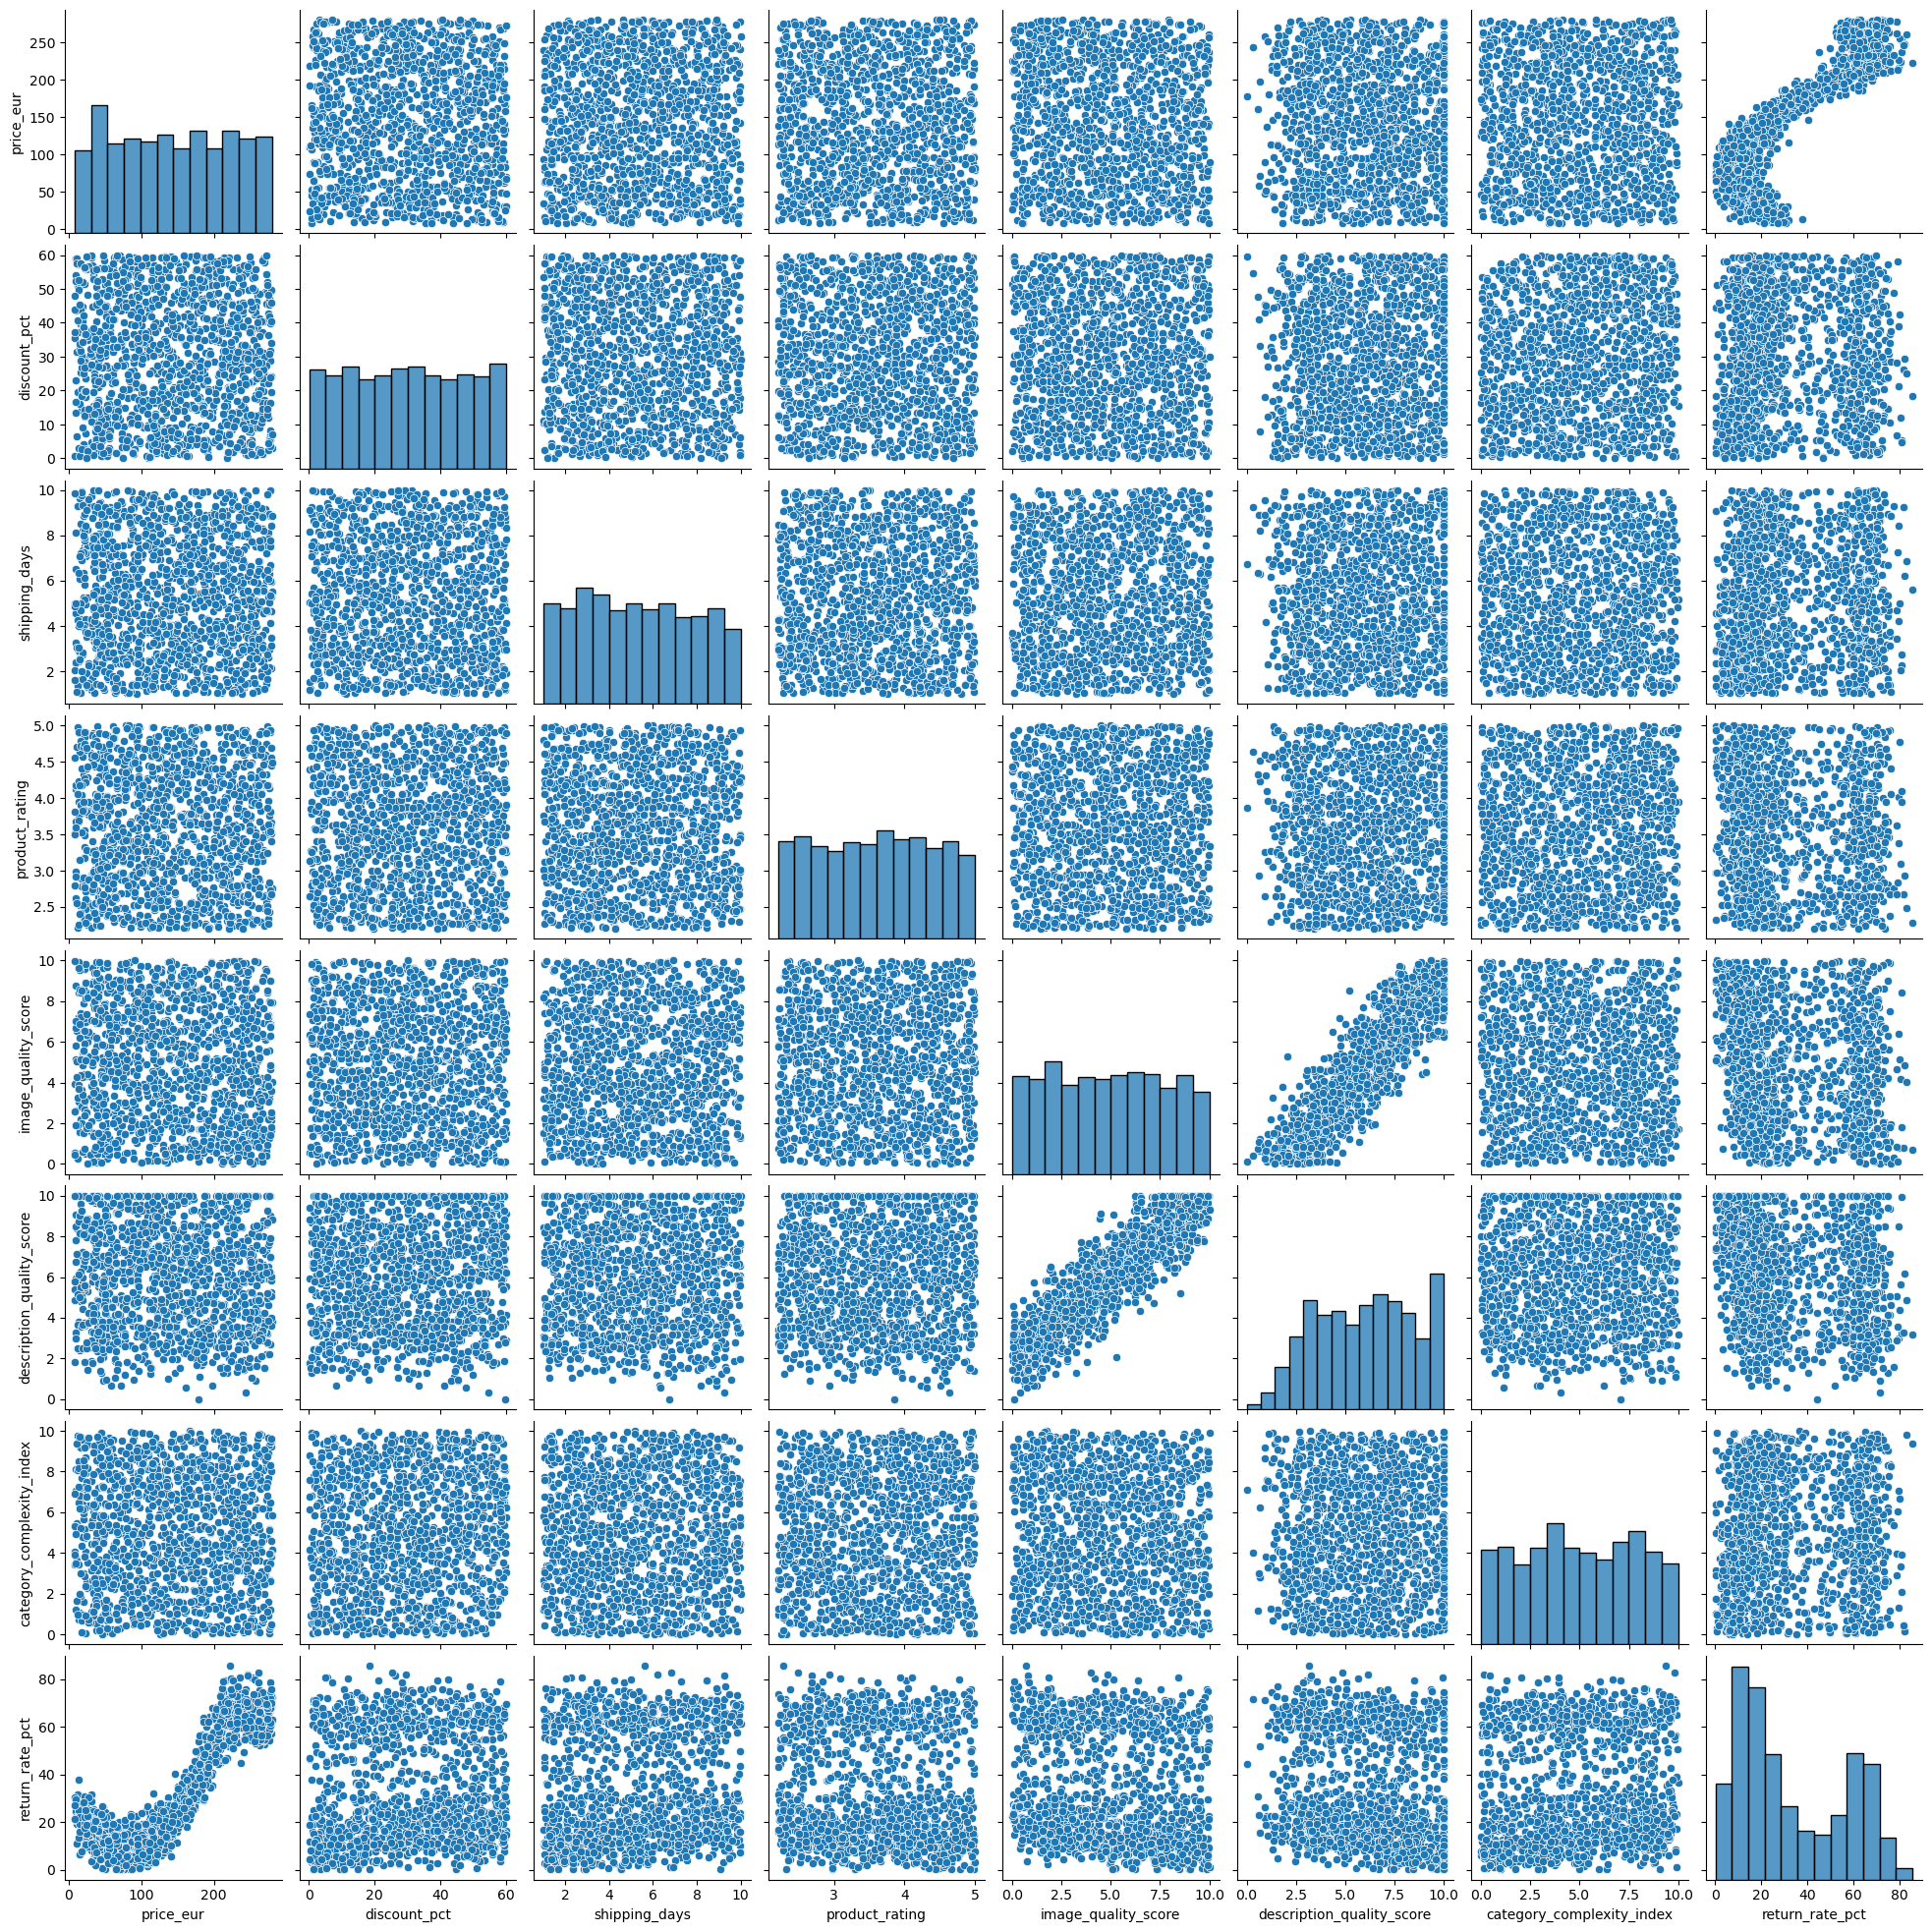

In [12]:
sns.pairplot(df.drop(columns=['size_variants_count', 'review_volume', 'size_mismatch_reports', 'holiday_campaign_flag', 'packaging_color_code']))

* focus on the bimodal shape of the return_rate_pct against features and its own distribution
* how to integrate polynomial/unimodal relationshiop between price_eur vs return_rate_pct
* linear correlation between image and description quality -> how to take care of multicolinearity? 
* notice the gap in description quality at the lower end of the range (+ weird skewed distribution)
* consider given correlation coefficients if some multicolinearity between less obvious features might affect our model
* do not forget about discrete and categorical variables, try to explain for example why holiday has a asymmetric distribution, check why size_variants_code looks bimodal, etc. (do not forget discrete stuff!)
* check for outliers if any!
* polynomial degree debate or another transformation
* how to combine strength of random forest regressor with polynomial transformation
* don't forget random seed bs!

In [13]:
df_train = pd.read_csv("data/track_k_ecommerce_returns_train.csv")
df_test = pd.read_csv("data/track_k_ecommerce_returns_test.csv")

X_train = df_train.drop(columns=['return_rate_pct'])
y_train = df_train[['return_rate_pct']]

X_test = df_test.drop(columns=['return_rate_pct'])
y_test = df_test[['return_rate_pct']]

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

def quick_test_model(model, X_train, y_train, X_test, y_test, return_model=False):
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)


    print(f"Train MSE:{mean_squared_error(y_pred_train, y_train)}")
    print(f"Test MSE:{mean_squared_error(y_pred_test, y_test)}")

    if return_model:
        return y_pred_train, y_pred_test, model
    
    return y_pred_train, y_pred_test


class BaselineMeanModel:
    def __init__(self):
        self.mean_ = None

    def fit(self, X, Y):
        self.mean_ = np.mean(Y)
    
    def predict(self, X):
        return np.full(shape=(X.shape[0],), fill_value=self.mean_)
    
class ThresModel:
    def __init__(self, threshold, feature, modelA=RandomForestRegressor(), modelB=RandomForestRegressor()):
        self.threshold_ = threshold
        self.feature_ = feature
        self.modelA_ = modelA
        self.modelB_ = modelB

    def _get_feature_values(self, X):
        """Extract feature values, handling both DataFrames and numpy arrays"""
        if isinstance(X, pd.DataFrame):
            return X[self.feature_].values
        else:
            # Assume feature_ is an integer index for numpy arrays
            return X[:, self.feature_]

    def fit(self, X, Y):
        # print(type(X), type(Y))
        feature_vals = self._get_feature_values(X)
        
        mask_A = feature_vals < self.threshold_
        mask_B = feature_vals >= self.threshold_
        
        X_A = X[mask_A]
        X_B = X[mask_B]
        Y_A = Y[mask_A]
        Y_B = Y[mask_B]

        self.modelA_.fit(X_A, Y_A)
        self.modelB_.fit(X_B, Y_B)

    def predict(self, X):
        feature_vals = self._get_feature_values(X)
        
        index_A = feature_vals < self.threshold_
        index_B = feature_vals >= self.threshold_

        X_A = X[index_A]
        X_B = X[index_B]

        Y_A = self.modelA_.predict(X_A)
        Y_B = self.modelB_.predict(X_B)

        Y = np.zeros(shape=(X.shape[0], 1))
        Y[index_A] = Y_A.reshape(-1, 1)
        Y[index_B] = Y_B.reshape(-1, 1)

        return Y


print("Baseline Mean Model")
quick_test_model(BaselineMeanModel(), X_train, y_train, X_test, y_test)
print("Linear regression with price only")
quick_test_model(LinearRegression(), X_train[['price_eur']], y_train, X_test[['price_eur']], y_test)
print("Linear regression with dropped column")
quick_test_model(LinearRegression(), X_train.drop(columns=['image_quality_score']), y_train, X_test.drop(columns=['image_quality_score']), y_test)

# 
# residual plot
# polynomial

NameError: name 'RandomForestRegressor' is not defined

In [ ]:
X = X_train
X
X_A = X[X['price_eur'] < 100]
X_A 

,price_eur,discount_pct,size_variants_count,shipping_days,product_rating,review_volume,image_quality_score,description_quality_score,size_mismatch_reports,category_complexity_index,holiday_campaign_flag,packaging_color_code
4,33.62,56.63,6,9.18,2.45,138,3.53,6.78,6,1.38,1,6
8,42.85,23.95,2,5.59,4.62,126,3.06,5.46,1,9.27,0,2
15,69.81,51.06,1,4.51,4.50,152,9.61,9.41,6,0.30,0,6
17,25.36,13.66,8,1.30,2.57,142,4.34,5.31,4,2.29,1,6
25,60.94,56.31,7,3.25,3.36,160,7.29,7.62,4,2.44,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
1277,36.09,35.29,6,4.46,3.23,132,0.82,2.50,5,2.50,1,6
1287,97.56,5.15,8,3.98,2.97,140,6.06,6.42,5,0.95,0,2
1293,95.23,10.12,3,2.33,3.40,132,3.50,7.72,3,2.06,0,5
1296,33.74,19.46,11,5.40,2.81,150,3.52,3.85,1,1.12,0,1


Linear regression
Train MSE:118.68086063613538
Test MSE:125.97856645086526


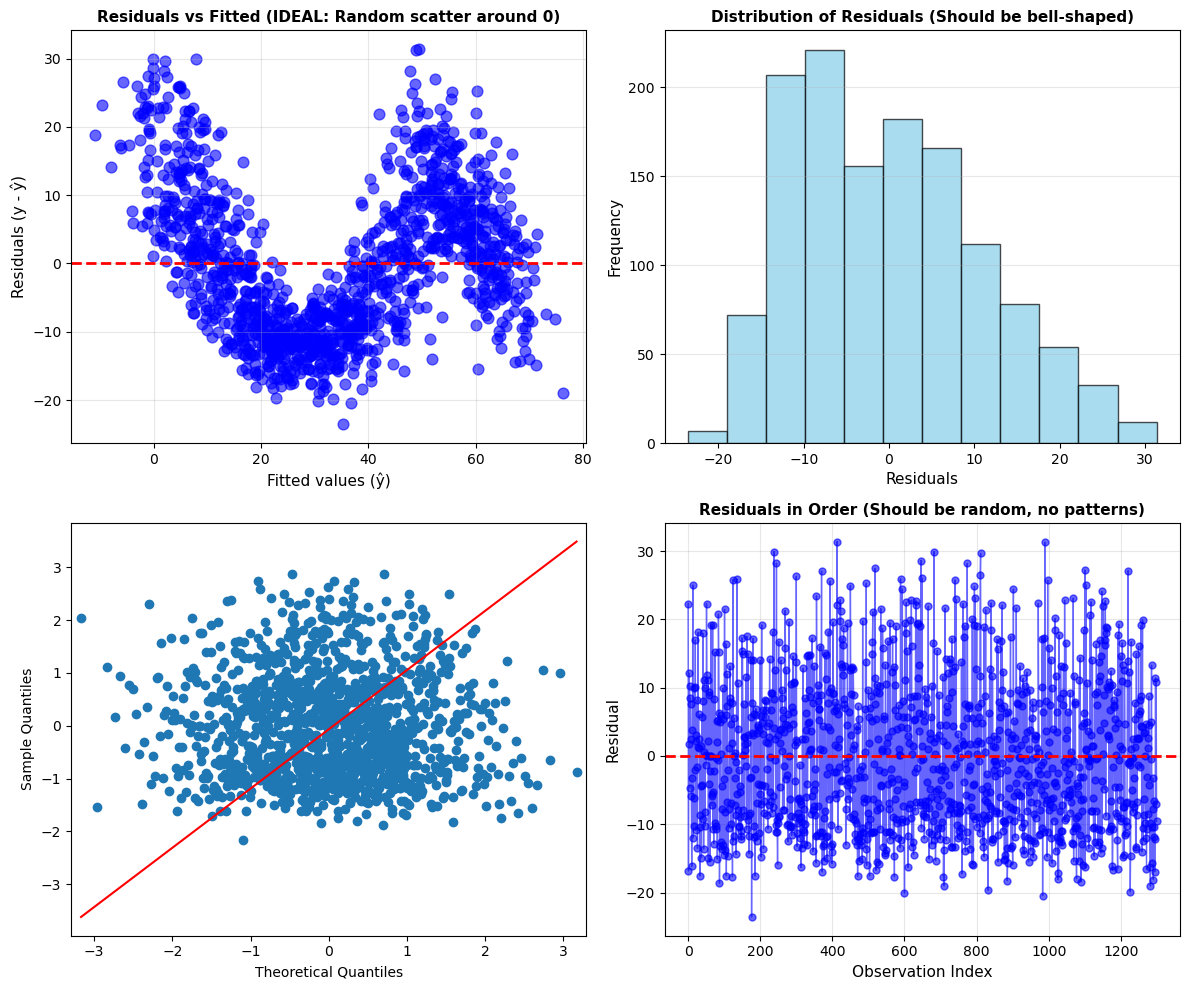

In [ ]:
print("Linear regression")
y_pred_train, y_pred_test =  quick_test_model(LinearRegression(), X_train, y_train, X_test, y_test)

# Calculate residuals
residuals_train = y_train - y_pred_train
residuals_test = y_test - y_pred_test

# Create comprehensive residual diagnostics
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Plot 1: Residuals vs Fitted (most important!)
axs[0, 0].scatter(y_pred_train, residuals_train, alpha=0.6, s=60, color='blue')
axs[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axs[0, 0].set_xlabel('Fitted values (ŷ)', fontsize=11)
axs[0, 0].set_ylabel('Residuals (y - ŷ)', fontsize=11)
axs[0, 0].set_title('Residuals vs Fitted (IDEAL: Random scatter around 0)', fontsize=11, fontweight='bold')
axs[0, 0].grid(alpha=0.3)

# Plot 2: Histogram
axs[0, 1].hist(residuals_train, bins=12, alpha=0.7, edgecolor='black', color='skyblue')
axs[0, 1].set_xlabel('Residuals', fontsize=11)
axs[0, 1].set_ylabel('Frequency', fontsize=11)
axs[0, 1].set_title('Distribution of Residuals (Should be bell-shaped)', fontsize=11, fontweight='bold')
axs[0, 1].grid(alpha=0.3, axis='y')

# Plot 3: QQ plot
# stats.probplot(residuals_train, dist="norm", plot=axs[1, 0])
# axs[1, 0].set_title('QQ Plot (Points should follow diagonal)', fontsize=11, fontweight='bold')
# axs[1, 0].grid(alpha=0.3)

import statsmodels.api as sm
from scipy import stats
fig = sm.qqplot(residuals_train, stats.norm, fit=True, line='q', ax=axs[1, 0])


# Plot 4: Residuals over observation index
axs[1, 1].plot(residuals_train, 'o-', alpha=0.6, linewidth=1, markersize=5, color='blue')
axs[1, 1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axs[1, 1].set_xlabel('Observation Index', fontsize=11)
axs[1, 1].set_ylabel('Residual', fontsize=11)
axs[1, 1].set_title('Residuals in Order (Should be random, no patterns)', fontsize=11, fontweight='bold')
axs[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Create polynomial features of degree 3 for price_eur
poly = PolynomialFeatures(degree=4, include_bias=False)
price_poly = poly.fit_transform(X_train[['price_eur']])

# Create new feature matrices with polynomial price
X_train_poly = X_train.copy()
X_train_poly = X_train_poly.drop(columns=['price_eur'])
X_train_poly = np.hstack([price_poly, X_train_poly])

X_test_poly = X_test.copy()
X_test_poly = X_test_poly.drop(columns=['price_eur'])
price_poly_test = poly.transform(X_test[['price_eur']])
X_test_poly = np.hstack([price_poly_test, X_test_poly])

# Test the model with polynomial features
print("Linear regression with degree 4 polynomial price")
y_pred_train, y_pred_test = quick_test_model(LinearRegression(), X_train_poly, y_train, X_test_poly, y_test)


# Create polynomial features of degree 3 for price_eur
poly = PolynomialFeatures(degree=5, include_bias=False)
price_poly = poly.fit_transform(X_train[['price_eur']])

# Create new feature matrices with polynomial price
X_train_poly = X_train.copy()
X_train_poly = X_train_poly.drop(columns=['price_eur'])
X_train_poly = np.hstack([price_poly, X_train_poly])

X_test_poly = X_test.copy()
X_test_poly = X_test_poly.drop(columns=['price_eur'])
price_poly_test = poly.transform(X_test[['price_eur']])
X_test_poly = np.hstack([price_poly_test, X_test_poly])

# Test the model with polynomial features
print("Linear regression with degree 5 polynomial price")
y_pred_train, y_pred_test = quick_test_model(LinearRegression(), X_train_poly, y_train, X_test_poly, y_test)

Linear regression with degree 4 polynomial price
Train MSE:27.762655482767155
Test MSE:26.859891890326377
Linear regression with degree 5 polynomial price
Train MSE:27.681189276421893
Test MSE:26.941444949364687


Linear regression with degree 5 polynomial price
Train MSE:27.681189276421893
Test MSE:26.941444949364687


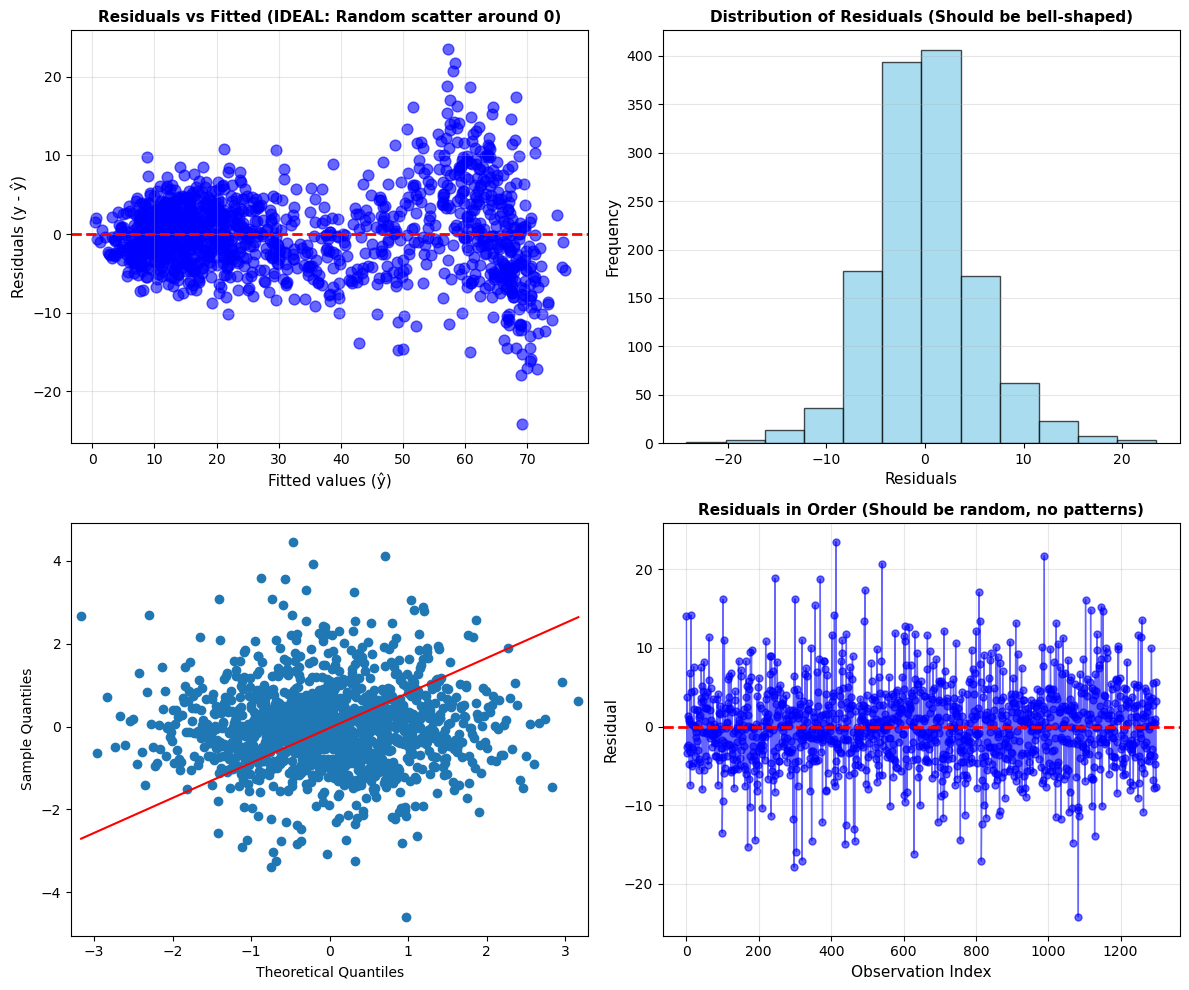

In [ ]:
print("Linear regression with degree 5 polynomial price")
y_pred_train, y_pred_test = quick_test_model(LinearRegression(), X_train_poly, y_train, X_test_poly, y_test)

# Calculate residuals
residuals_train = y_train - y_pred_train
residuals_test = y_test - y_pred_test

# Create comprehensive residual diagnostics
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Plot 1: Residuals vs Fitted (most important!)
axs[0, 0].scatter(y_pred_train, residuals_train, alpha=0.6, s=60, color='blue')
axs[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axs[0, 0].set_xlabel('Fitted values (ŷ)', fontsize=11)
axs[0, 0].set_ylabel('Residuals (y - ŷ)', fontsize=11)
axs[0, 0].set_title('Residuals vs Fitted (IDEAL: Random scatter around 0)', fontsize=11, fontweight='bold')
axs[0, 0].grid(alpha=0.3)

# Plot 2: Histogram
axs[0, 1].hist(residuals_train, bins=12, alpha=0.7, edgecolor='black', color='skyblue')
axs[0, 1].set_xlabel('Residuals', fontsize=11)
axs[0, 1].set_ylabel('Frequency', fontsize=11)
axs[0, 1].set_title('Distribution of Residuals (Should be bell-shaped)', fontsize=11, fontweight='bold')
axs[0, 1].grid(alpha=0.3, axis='y')

# Plot 3: QQ plot
# stats.probplot(residuals_train, dist="norm", plot=axs[1, 0])
# axs[1, 0].set_title('QQ Plot (Points should follow diagonal)', fontsize=11, fontweight='bold')
# axs[1, 0].grid(alpha=0.3)

import statsmodels.api as sm
from scipy import stats
fig = sm.qqplot(residuals_train, stats.norm, fit=True, line='q', ax=axs[1, 0])


# Plot 4: Residuals over observation index
axs[1, 1].plot(residuals_train, 'o-', alpha=0.6, linewidth=1, markersize=5, color='blue')
axs[1, 1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axs[1, 1].set_xlabel('Observation Index', fontsize=11)
axs[1, 1].set_ylabel('Residual', fontsize=11)
axs[1, 1].set_title('Residuals in Order (Should be random, no patterns)', fontsize=11, fontweight='bold')
axs[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Random forest classifier with poly


c:\Users\Toma\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Train MSE:3.899206279707695
Test MSE:25.461912889771433
(1300,)
(1300, 1)
(1300, 1)
(1300, 1)


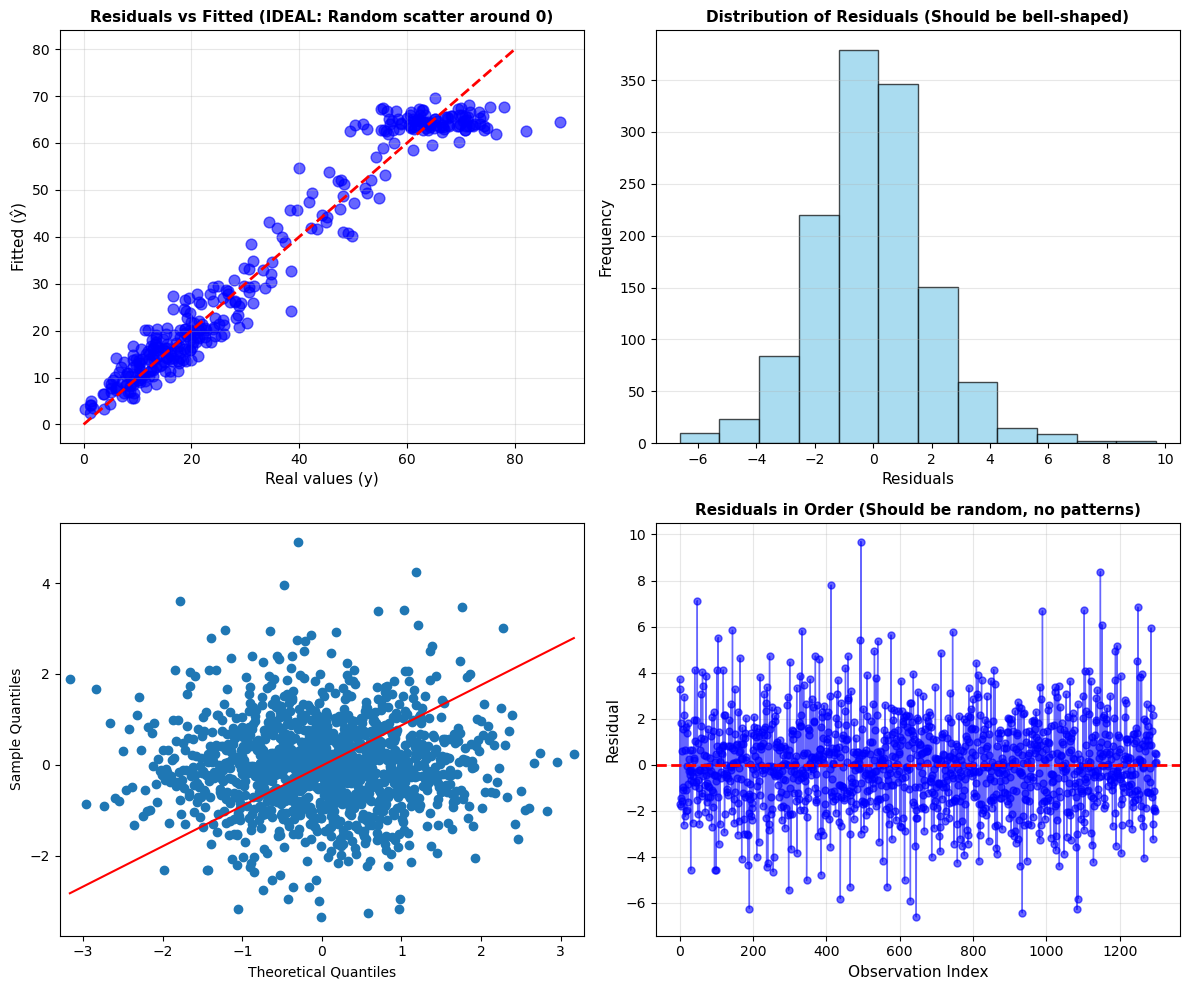

In [ ]:
from sklearn.ensemble import RandomForestRegressor
print("Random forest classifier with poly")
y_pred_train, y_pred_test = quick_test_model(RandomForestRegressor(), X_train_poly, y_train, X_test_poly, y_test)

print(y_pred_train.shape)
print(y_train.shape)
y_pred_train = np.array(y_pred_train).reshape(-1,1)
y_pred_test = np.array(y_pred_test).reshape(-1,1)
print(y_pred_train.shape)
print(y_train.shape)
# Calculate residuals
residuals_train = y_train - y_pred_train
residuals_test = y_test - y_pred_test

# Create comprehensive residual diagnostics
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# # Plot 1: Residuals vs Fitted (most important!)
# axs[0, 0].scatter(y_pred_train, residuals_train, alpha=0.6, s=60, color='blue')
# axs[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=2)
# axs[0, 0].set_xlabel('Fitted values (ŷ)', fontsize=11)
# axs[0, 0].set_ylabel('Residuals (y - ŷ)', fontsize=11)
# axs[0, 0].set_title('Residuals vs Fitted (IDEAL: Random scatter around 0)', fontsize=11, fontweight='bold')
# axs[0, 0].grid(alpha=0.3)

# Plot 1: Residuals vs Fitted (most important!)
axs[0, 0].scatter(y_test, y_pred_test, alpha=0.6, s=60, color='blue')
axs[0, 0].plot(np.linspace(0,80,100), np.linspace(0,80,100), color='red', linestyle='--', linewidth=2)
axs[0, 0].set_xlabel('Real values (y)', fontsize=11)
axs[0, 0].set_ylabel('Fitted (ŷ)', fontsize=11)
axs[0, 0].set_title('Residuals vs Fitted (IDEAL: Random scatter around 0)', fontsize=11, fontweight='bold')
axs[0, 0].grid(alpha=0.3)

# Plot 2: Histogram
axs[0, 1].hist(residuals_train, bins=12, alpha=0.7, edgecolor='black', color='skyblue')
axs[0, 1].set_xlabel('Residuals', fontsize=11)
axs[0, 1].set_ylabel('Frequency', fontsize=11)
axs[0, 1].set_title('Distribution of Residuals (Should be bell-shaped)', fontsize=11, fontweight='bold')
axs[0, 1].grid(alpha=0.3, axis='y')

# Plot 3: QQ plot
# stats.probplot(residuals_train, dist="norm", plot=axs[1, 0])
# axs[1, 0].set_title('QQ Plot (Points should follow diagonal)', fontsize=11, fontweight='bold')
# axs[1, 0].grid(alpha=0.3)

import statsmodels.api as sm
from scipy import stats
fig = sm.qqplot(residuals_train, stats.norm, fit=True, line='q', ax=axs[1, 0])


# Plot 4: Residuals over observation index
axs[1, 1].plot(residuals_train, 'o-', alpha=0.6, linewidth=1, markersize=5, color='blue')
axs[1, 1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axs[1, 1].set_xlabel('Observation Index', fontsize=11)
axs[1, 1].set_ylabel('Residual', fontsize=11)
axs[1, 1].set_title('Residuals in Order (Should be random, no patterns)', fontsize=11, fontweight='bold')
axs[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn import tree
print("Decision tree")
y_pred_train, y_pred_test, decision_tree_model = quick_test_model(tree.DecisionTreeRegressor(max_depth=5), X_train, y_train, X_test, y_test, return_model=True)
print("Random forest classifier")
y_pred_train, y_pred_test = quick_test_model(RandomForestRegressor(), X_train, y_train, X_test, y_test)

print("Decision tree with poly")
y_pred_train, y_pred_test = quick_test_model(tree.DecisionTreeRegressor(), X_train_poly, y_train, X_test_poly, y_test)
print("Random forest classifier with poly")
y_pred_train, y_pred_test, model = quick_test_model(RandomForestRegressor(), X_train_poly, y_train, X_test_poly, y_test, return_model=True)
model

Decision tree
Train MSE:29.564884212275278
Test MSE:35.4848768602667
Random forest classifier


c:\Users\Toma\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Train MSE:3.795206181792312
Test MSE:25.76341340634285
Decision tree with poly
Train MSE:1.7777814871266794e-36
Test MSE:49.198062571428565
Random forest classifier with poly


c:\Users\Toma\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Train MSE:3.9138193641000045
Test MSE:26.156252462685714


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


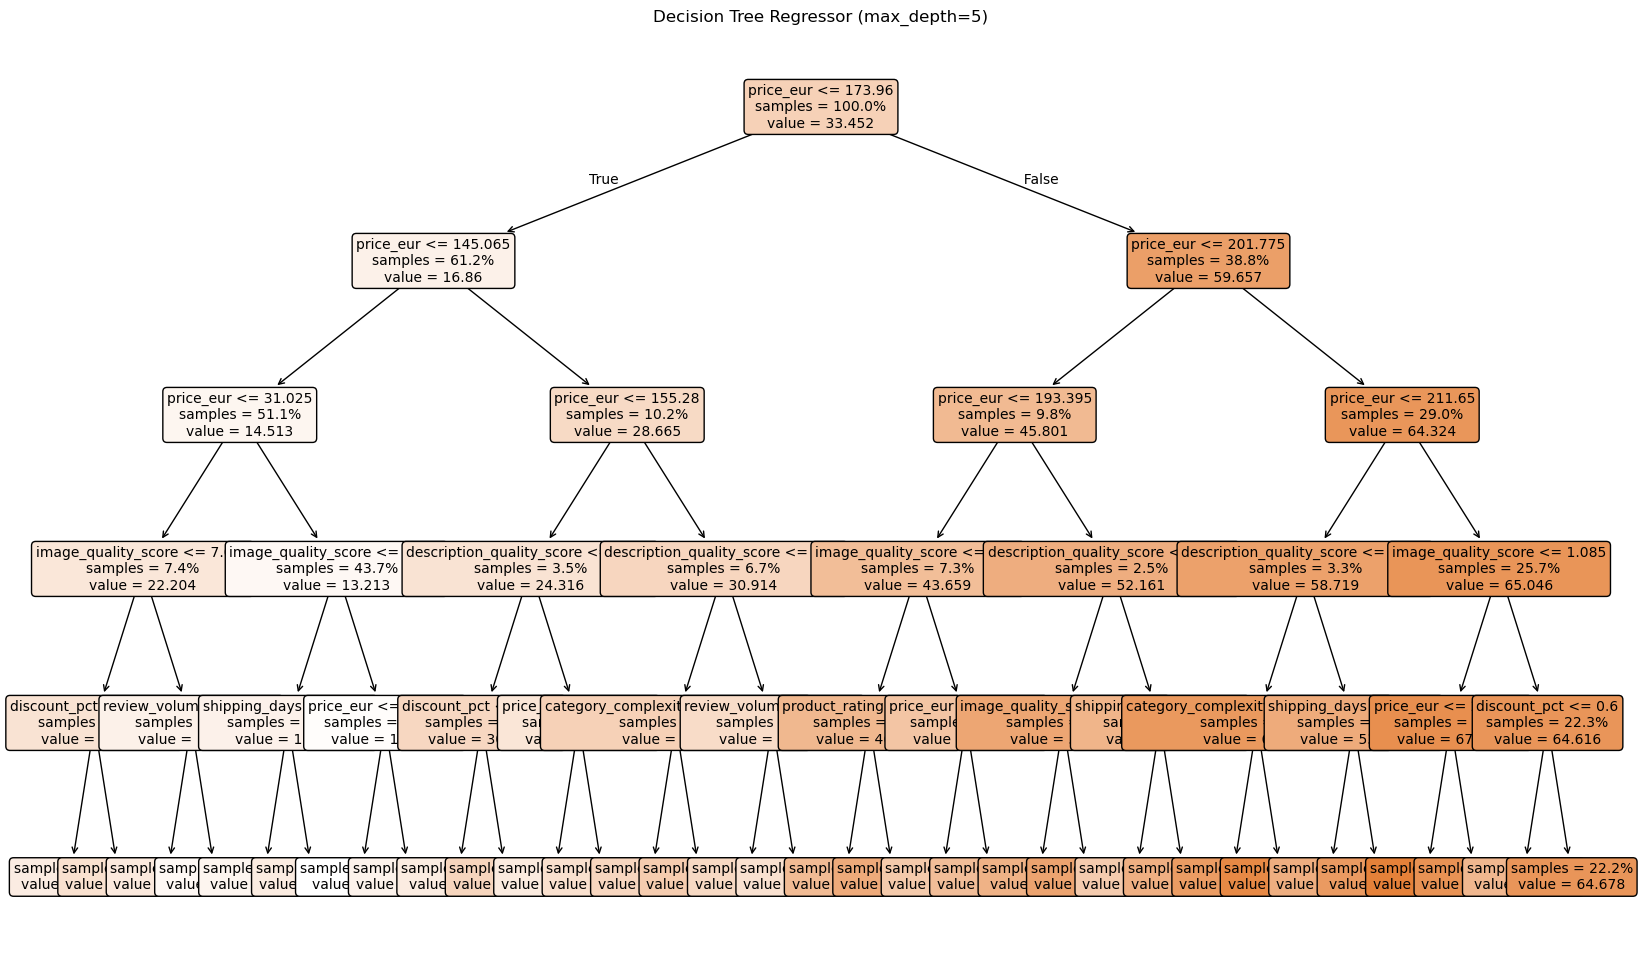

In [ ]:
plt.figure(figsize=(20, 12))
tree.plot_tree(
    decision_tree_model,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    proportion=True,
    impurity=False,
    fontsize=10
)
plt.title("Decision Tree Regressor (max_depth=5)")
plt.show()

C:\Users\Toma\AppData\Local\Temp\ipykernel_12896\4101051909.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis")


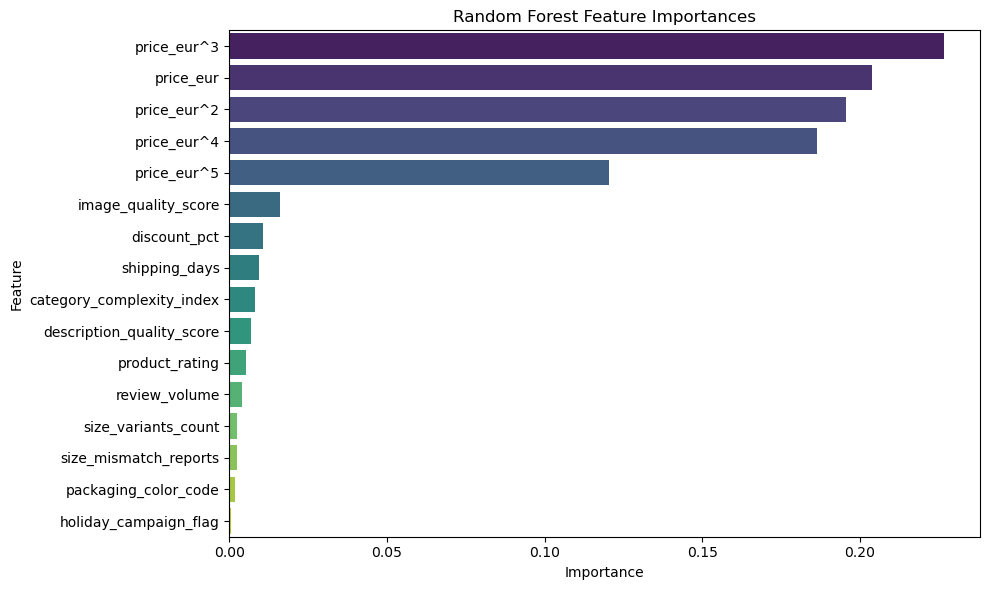

In [ ]:
poly_feature_names = [f"price_eur^{i}" if i > 1 else "price_eur" for i in range(1, 6)]
other_features = [col for col in X_train.columns if col != "price_eur"]
feature_names = poly_feature_names + other_features

importances = model.feature_importances_
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis")
plt.title("Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

C:\Users\Toma\AppData\Local\Temp\ipykernel_12896\3261598571.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=perm_imp_df, palette="viridis", errorbar='sd')


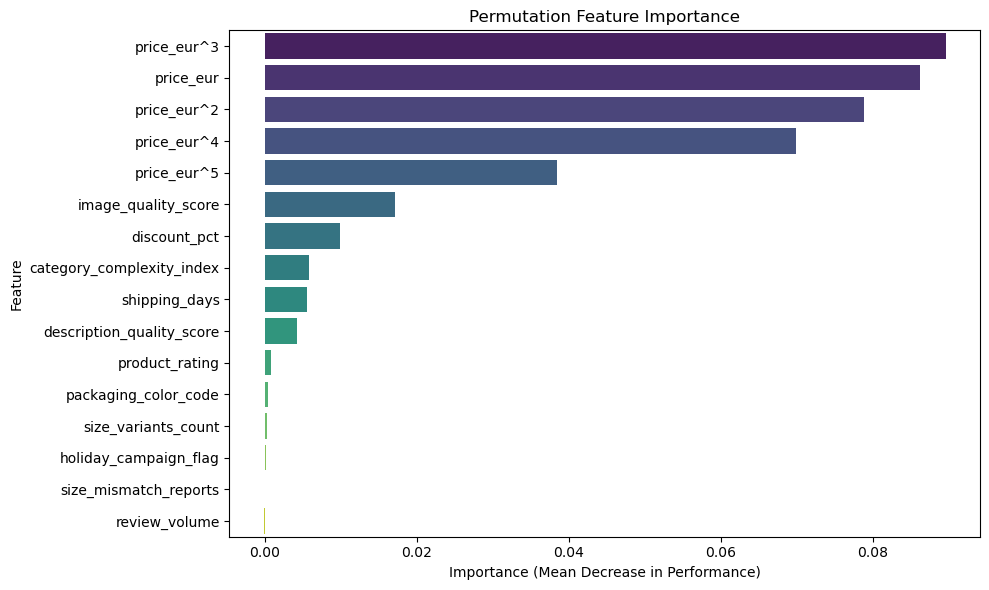

In [ ]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on test set
perm_importance = permutation_importance(model, X_test_poly, y_test, n_repeats=10, random_state=42)

# Create a DataFrame for better visualization
perm_imp_df = pd.DataFrame({
    'feature': feature_names,
    'importance': perm_importance.importances_mean,
    'std': perm_importance.importances_std
}).sort_values('importance', ascending=False)

# Plot permutation importance
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=perm_imp_df, palette="viridis", errorbar='sd')
plt.title("Permutation Feature Importance")
plt.xlabel("Importance (Mean Decrease in Performance)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import Ridge, Lasso



print("Ridge regression with degree 5 polynomial price")
y_pred_train, y_pred_test = quick_test_model(Ridge(alpha=2009), X_train_poly, y_train, X_test_poly, y_test)

print("Lasso regression with degree 5 polynomial price")
y_pred_train, y_pred_test = quick_test_model(Lasso(), X_train_poly, y_train, X_test_poly, y_test)

Ridge regression with degree 5 polynomial price
Train MSE:28.58366145398582
Test MSE:26.579039093627696
Lasso regression with degree 5 polynomial price
Train MSE:29.829566468691706
Test MSE:27.847353988116826


c:\Users\Toma\anaconda3\Lib\site-packages\scipy\_lib\_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=8.79632e-24): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
c:\Users\Toma\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.246e+04, tolerance: 6.875e+01
  model = cd_fast.enet_coordinate_descent(


c:\Users\Toma\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.848e+04, tolerance: 6.875e+01
  model = cd_fast.enet_coordinate_descent(
c:\Users\Toma\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.848e+04, tolerance: 6.875e+01
  model = cd_fast.enet_coordinate_descent(
c:\Users\Toma\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.848e+04, tolerance: 

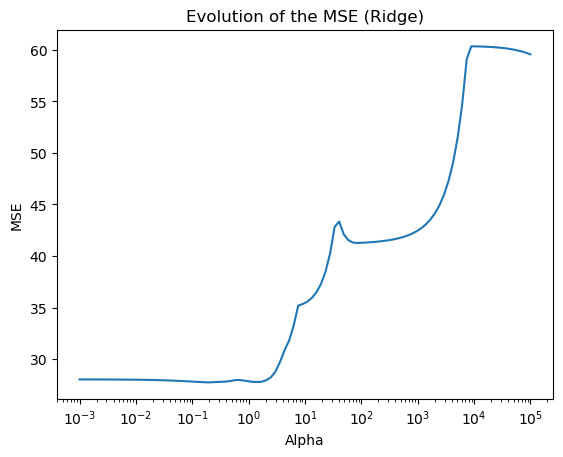

best mse : 27.7504211186267
alpha correspondant 0.18307382802953698


In [ ]:
from sklearn.linear_model import Ridge
alphas = np.logspace(-3, 5, 100)
ridge_mse_list = []
ridge_coefs_list = []
for a in alphas:
    modele_ridge = Lasso(alpha = a)
    modele_ridge.fit(X_train_poly,y_train)
    y_pred_ridge = modele_ridge.predict(X_test_poly)

    mse_ridge = mean_squared_error(y_test, y_pred_ridge)
    ridge_mse_list.append(mse_ridge)

    ridge_coef = modele_ridge.coef_
    ridge_coefs_list.append(ridge_coef)

plt.plot(alphas, ridge_mse_list)
plt.xscale('log')
plt.xlabel("Alpha")
plt.ylabel("MSE")
plt.title("Evolution of the MSE (Ridge)")
plt.savefig('ridge_mse.png', dpi=300, bbox_inches='tight')

plt.show()


#valeur optimal
meilleur_mse_ridge = min(ridge_mse_list)
print("best mse :",meilleur_mse_ridge)
position = ridge_mse_list.index(meilleur_mse_ridge)
print("alpha correspondant", alphas[position])

threshold model

Random forest classifier with poly
<class 'numpy.ndarray'> <class 'pandas.core.frame.DataFrame'>


c:\Users\Toma\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Users\Toma\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Train MSE:3.866560360107695
Test MSE:25.54954502780002
(1300, 1)
(1300, 1)
(1300, 1)
(1300, 1)


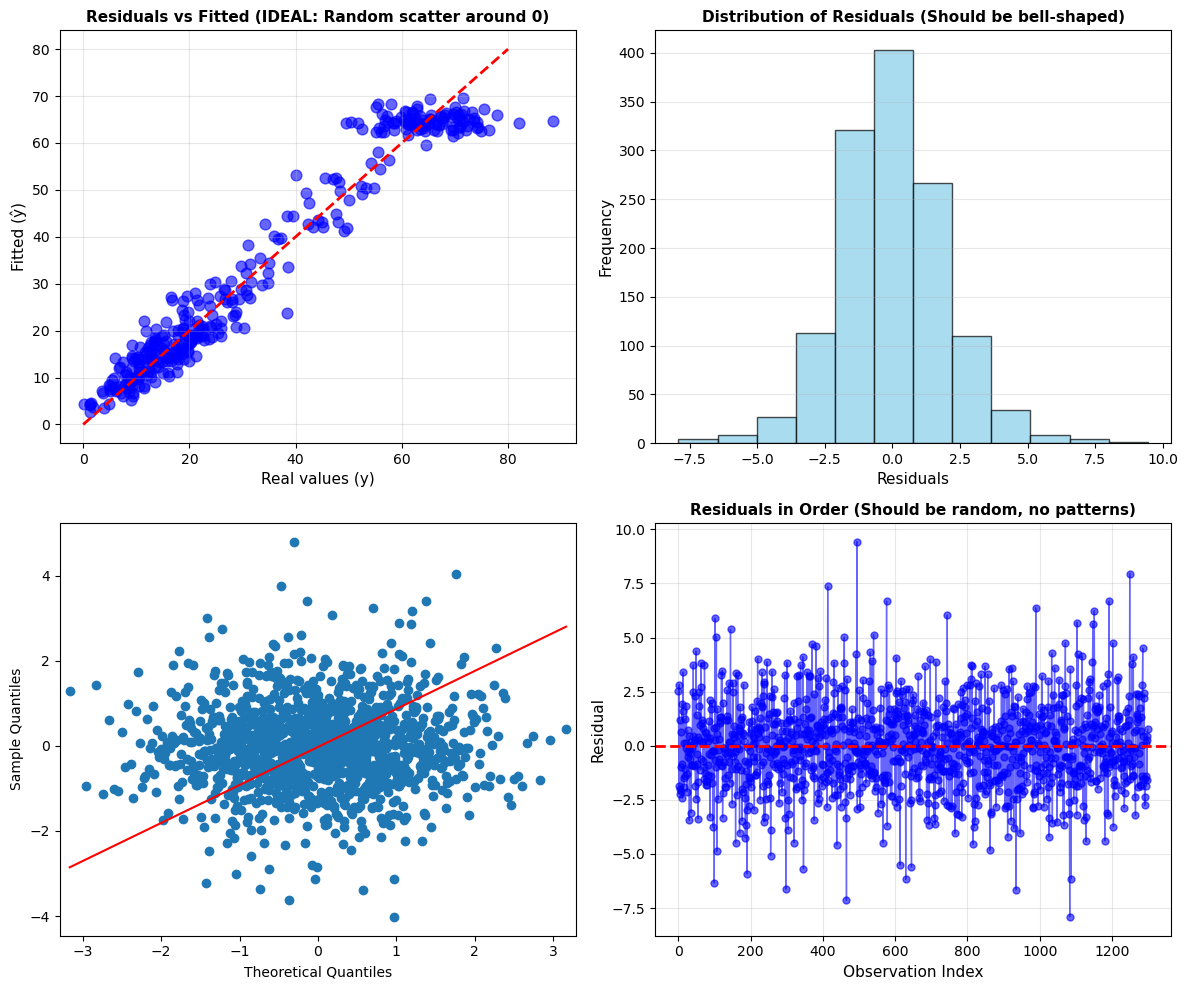

In [ ]:
from sklearn.ensemble import RandomForestRegressor
print("Random forest classifier with poly")

y_pred_train, y_pred_test, model = quick_test_model(ThresModel(174,0, RandomForestRegressor(), RandomForestRegressor()), X_train_poly, y_train, X_test_poly, y_test, return_model=True)

print(y_pred_train.shape)
print(y_train.shape)
y_pred_train = np.array(y_pred_train).reshape(-1,1)
y_pred_test = np.array(y_pred_test).reshape(-1,1)
print(y_pred_train.shape)
print(y_train.shape)
# Calculate residuals
residuals_train = y_train - y_pred_train
residuals_test = y_test - y_pred_test

# Create comprehensive residual diagnostics
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# # Plot 1: Residuals vs Fitted (most important!)
# axs[0, 0].scatter(y_pred_train, residuals_train, alpha=0.6, s=60, color='blue')
# axs[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=2)
# axs[0, 0].set_xlabel('Fitted values (ŷ)', fontsize=11)
# axs[0, 0].set_ylabel('Residuals (y - ŷ)', fontsize=11)
# axs[0, 0].set_title('Residuals vs Fitted (IDEAL: Random scatter around 0)', fontsize=11, fontweight='bold')
# axs[0, 0].grid(alpha=0.3)

# Plot 1: Residuals vs Fitted (most important!)
axs[0, 0].scatter(y_test, y_pred_test, alpha=0.6, s=60, color='blue')
axs[0, 0].plot(np.linspace(0,80,100), np.linspace(0,80,100), color='red', linestyle='--', linewidth=2)
axs[0, 0].set_xlabel('Real values (y)', fontsize=11)
axs[0, 0].set_ylabel('Fitted (ŷ)', fontsize=11)
axs[0, 0].set_title('Residuals vs Fitted (IDEAL: Random scatter around 0)', fontsize=11, fontweight='bold')
axs[0, 0].grid(alpha=0.3)

# Plot 2: Histogram
axs[0, 1].hist(residuals_train, bins=12, alpha=0.7, edgecolor='black', color='skyblue')
axs[0, 1].set_xlabel('Residuals', fontsize=11)
axs[0, 1].set_ylabel('Frequency', fontsize=11)
axs[0, 1].set_title('Distribution of Residuals (Should be bell-shaped)', fontsize=11, fontweight='bold')
axs[0, 1].grid(alpha=0.3, axis='y')

# Plot 3: QQ plot
# stats.probplot(residuals_train, dist="norm", plot=axs[1, 0])
# axs[1, 0].set_title('QQ Plot (Points should follow diagonal)', fontsize=11, fontweight='bold')
# axs[1, 0].grid(alpha=0.3)

import statsmodels.api as sm
from scipy import stats
fig = sm.qqplot(residuals_train, stats.norm, fit=True, line='q', ax=axs[1, 0])


# Plot 4: Residuals over observation index
axs[1, 1].plot(residuals_train, 'o-', alpha=0.6, linewidth=1, markersize=5, color='blue')
axs[1, 1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axs[1, 1].set_xlabel('Observation Index', fontsize=11)
axs[1, 1].set_ylabel('Residual', fontsize=11)
axs[1, 1].set_title('Residuals in Order (Should be random, no patterns)', fontsize=11, fontweight='bold')
axs[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
for threshold in range(50, 250, 10):
    print(f"Threshold: {threshold}")
    y_pred_train, y_pred_test, model = quick_test_model(ThresModel(threshold,0, RandomForestRegressor(), RandomForestRegressor()), X_train_poly, y_train, X_test_poly, y_test, return_model=True)
    


Threshold: 50
Train MSE:3.8148110600000074
Test MSE:25.210594908371423
Threshold: 60
Train MSE:3.824801875792313
Test MSE:25.382288080599995
Threshold: 70
Train MSE:3.7515369618000043
Test MSE:25.453721964571415
Threshold: 80
Train MSE:3.9401521876692347
Test MSE:25.91577312845714
Threshold: 90
Train MSE:3.8876994952461588
Test MSE:25.812918438371437
Threshold: 100
Train MSE:3.8033305574076963
Test MSE:25.597508338571423
Threshold: 110
Train MSE:3.7612774977307737
Test MSE:25.713868942942863
Threshold: 120
Train MSE:3.903626917661544
Test MSE:25.376052148028574
Threshold: 130
Train MSE:3.940763656153851
Test MSE:25.79125508822858
Threshold: 140
Train MSE:3.8933261629000055
Test MSE:25.589258766371433
Threshold: 150
Train MSE:3.899243611338468
Test MSE:25.669345202600006
Threshold: 160
Train MSE:3.886669496807699
Test MSE:26.600111818857133
Threshold: 170
Train MSE:3.8879230909307725
Test MSE:25.96424743122857
Threshold: 180
Train MSE:3.9668910762000054
Test MSE:25.666278520800006
Thres

In [ ]:
import torch
print(torch.version)
print(torch.cuda)

<module 'torch.version' from 'c:\\Users\\Toma\\anaconda3\\Lib\\site-packages\\torch\\version.py'>
<module 'torch.cuda' from 'c:\\Users\\Toma\\anaconda3\\Lib\\site-packages\\torch\\cuda\\__init__.py'>


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Convert data to tensors
X_train_tensor = torch.FloatTensor(X_train_poly)
y_train_tensor = torch.FloatTensor(y_train.values)
X_test_tensor = torch.FloatTensor(X_test_poly)
y_test_tensor = torch.FloatTensor(y_test.values)

# Create DataLoader for batching
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Define the fully connected neural network
class FCN(nn.Module):
    def __init__(self, input_size, hidden_sizes=[128, 64, 32]):
        super(FCN, self).__init__()
        layers = []
        prev_size = input_size
        
        # Hidden layers with ReLU activation
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(prev_size, hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(0.2))  # Dropout for regularization
            prev_size = hidden_size
        
        # Output layer (regression - single output)
        layers.append(nn.Linear(prev_size, 1))
        
        self.network = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.network(x)

# Initialize model
input_size = X_train_poly.shape[1]
model = FCN(input_size, hidden_sizes=[128, 64, 32])

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training loop
num_epochs = 100
train_losses = []
test_losses = []

for epoch in range(num_epochs):
    # Training
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    train_losses.append(train_loss)
    
    # Evaluation on test set
    with torch.no_grad():
        y_pred_test = model(X_test_tensor)
        test_loss = criterion(y_pred_test, y_test_tensor)
        test_losses.append(test_loss.item())
    
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}/{num_epochs}, Train MSE: {train_loss:.4f}, Test MSE: {test_loss.item():.4f}")

print("\nTraining complete!")
print(f"Final Test MSE: {test_losses[-1]:.4f}")

# Plot training history
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train MSE', linewidth=2)
plt.plot(test_losses, label='Test MSE', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Neural Network Training History')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


NameError: name 'X_train_poly' is not defined